In [6]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter1d

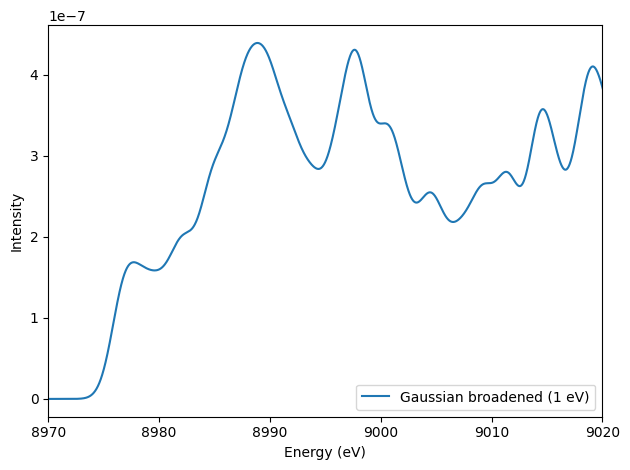

In [25]:
data = np.loadtxt("Cu_GW.dat")

energy_GW = data[:, 0]
intensity = data[:, 1]

# Gaussian broadening width in eV
sigma_eV = 1

# convert from eV to number of points
dE = energy_GW[1] - energy_GW[0]
sigma_pts = sigma_eV / dE

intensity_broad = gaussian_filter1d(intensity, sigma=sigma_pts)

# plt.plot(energy, intensity, label="raw")
plt.plot(energy_GW+120, intensity_broad, label=f"Gaussian broadened ({sigma_eV} eV)")
plt.xlabel("Energy (eV)")
plt.ylabel("Intensity")
plt.xlim(8970, 9020)
plt.legend()
plt.tight_layout()
plt.show()

In [26]:
data = np.loadtxt("Cu_PBE.dat")

energy = data[:, 0]
intensity = data[:, 1]

# Gaussian broadening width in eV
sigma_eV = 1

# convert from eV to number of points
dE = energy[1] - energy[0]
sigma_pts = sigma_eV / dE

intensity_broad = gaussian_filter1d(intensity, sigma=sigma_pts)

# plt.plot(energy, intensity, label="raw")
plt.plot(energy+120, intensity_broad, label=f"Gaussian broadened ({sigma_eV} eV)")
plt.xlabel("Energy (eV)")
plt.ylabel("Intensity")
plt.xlim(8970, 9010)
plt.legend()
plt.tight_layout()
plt.show()

/var/folders/x6/czb1zz7s48dbh_q7y6q44zvm0000gp/T/ipykernel_66467/850346391.py:1: UserWarning: loadtxt: input contained no data: "Cu_PBE.dat"
  data = np.loadtxt("Cu_PBE.dat")


IndexError: too many indices for array: array is 1-dimensional, but 2 were indexed

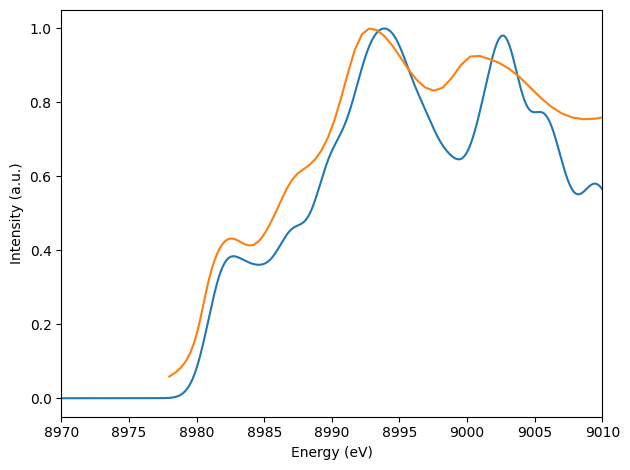

In [4]:
data = np.loadtxt("Cu_xmu.dat", comments="#")
omega = data[:, 0]
mu = data[:, 3]

plt.plot(energy+125, intensity_broad/max(intensity_broad), label=f"Gaussian broadened ({sigma_eV} eV)")
plt.plot(omega-8, mu/max(mu), label="feff")
plt.xlabel("Energy (eV)")
plt.ylabel("Intensity (a.u.)")
plt.xlim(8970, 9010)
plt.tight_layout()
plt.show()

In [7]:
df = pd.read_csv("260324_export_XAS_Exp_ref_stds.dat", sep="\t")

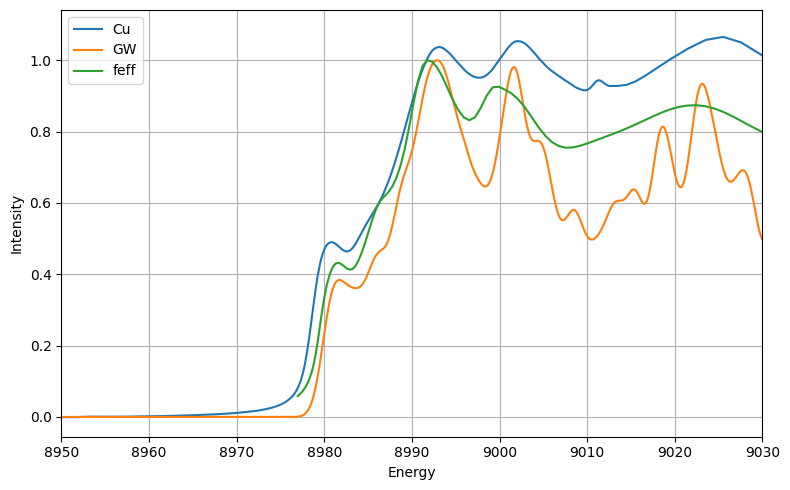

In [27]:
# Keep the first 4 columns only for this plot
energy_exp = df.iloc[:, 0]
cu = df.iloc[:, 1]
cu2o = df.iloc[:, 2]
cuo = df.iloc[:, 3]

# Plot
plt.figure(figsize=(8, 5))
plt.plot(energy_exp, cu, label="Cu")
# plt.plot(energy_exp, cu2o, label="Cu2O")
# plt.plot(energy_exp, cuo, label="CuO")


plt.plot(energy_GW+124, intensity_broad/max(intensity_broad), label="GW")
plt.plot(omega-9, mu/max(mu), label="FEFF")


plt.xlabel("Energy")
plt.ylabel("Intensity")
plt.xlim([8950, 9030])
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()